# Customer Shopping Behavior Analysis

**Business question:** How can the company leverage consumer shopping data to identify trends, improve customer engagement, and optimize marketing and product strategies?

**Notebook flow:** load → inspect → clean → feature engineering → data-quality checks → EDA on business drivers → statistical tests → export → load to PostgreSQL.

## Data limitations (read before interpreting results)
1. **No date/time column.** Time trends cannot be analysed. `Season` is the only time-related field.
2. **One row per customer** (`customer_id` is unique, verified below). "Customers" and "transactions" are the same unit, so true repeat-purchase behaviour over time cannot be observed. `previous_purchases` is the only loyalty signal.
3. **No online/offline flag.** `shipping_type = 'Store Pickup'` is used as an *offline proxy* only.
4. **The data looks synthetic** (near-uniform distributions for age, purchase amount and previous purchases), so many group differences are small. Findings are reported with baselines and significance tests so that "no real difference" is stated honestly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv('customer_shopping_behavior.csv')

In [2]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [4]:
df.describe(include='all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


In [5]:
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

We will replace the NULL reviews with the median rating of the category that the item belongs to.

In [6]:
df['Review Rating'] = df.groupby('Category')['Review Rating'].transform(lambda x: x.fillna(x.median()))

In [7]:
df.isnull().sum()

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

The column names mix upper/lower case and contain spaces. We convert them to lowercase snake_case.
Example: `Customer ID` → `customer_id`

In [8]:
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ', '_')
df = df.rename(columns={'purchase_amount_(usd)': 'purchase_amount'})
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

## Data-quality checks

In [9]:
# 1. Duplicates
print("Duplicate customer_id values :", df['customer_id'].duplicated().sum())
print("Fully duplicated rows        :", df.duplicated().sum())

# 2. Unique values per categorical column (look for inconsistent spellings / case)
cat_cols = df.select_dtypes(include=['object', 'string']).columns
for c in cat_cols:
    n = df[c].nunique()
    print(f"\n{c}  ({n} unique)")
    if n <= 10:
        print(df[c].value_counts().to_dict())

# 3. Outliers in purchase_amount (IQR rule)
q1, q3 = df['purchase_amount'].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = ((df['purchase_amount'] < lo) | (df['purchase_amount'] > hi)).sum()
print(f"\npurchase_amount fences: [{lo:.1f}, {hi:.1f}] -> outliers: {n_out}")

# 4. Value ranges
print("\nreview_rating range:", df['review_rating'].min(), "-", df['review_rating'].max())
print("age range          :", df['age'].min(), "-", df['age'].max())
print("previous_purchases :", df['previous_purchases'].min(), "-", df['previous_purchases'].max())

Duplicate customer_id values : 0
Fully duplicated rows        : 0

gender  (2 unique)
{'Male': 2652, 'Female': 1248}

item_purchased  (25 unique)

category  (4 unique)
{'Clothing': 1737, 'Accessories': 1240, 'Footwear': 599, 'Outerwear': 324}

location  (50 unique)

size  (4 unique)
{'M': 1755, 'L': 1053, 'S': 663, 'XL': 429}

color  (25 unique)

season  (4 unique)
{'Spring': 999, 'Fall': 975, 'Winter': 971, 'Summer': 955}

subscription_status  (2 unique)
{'No': 2847, 'Yes': 1053}

shipping_type  (6 unique)
{'Free Shipping': 675, 'Standard': 654, 'Store Pickup': 650, 'Next Day Air': 648, 'Express': 646, '2-Day Shipping': 627}

discount_applied  (2 unique)
{'No': 2223, 'Yes': 1677}

promo_code_used  (2 unique)
{'No': 2223, 'Yes': 1677}

payment_method  (6 unique)
{'PayPal': 677, 'Credit Card': 671, 'Cash': 670, 'Debit Card': 636, 'Venmo': 634, 'Bank Transfer': 612}

frequency_of_purchases  (7 unique)
{'Every 3 Months': 584, 'Annually': 572, 'Quarterly': 563, 'Monthly': 553, 'Bi-Weekly':

## Feature engineering

### 1. `age_group` (explicit bins, ordered youngest to oldest)
The earlier version used `pd.qcut` (quartiles), which hid the actual age ranges. Explicit bins give identical groups but are documented and stable.

| age_group | age range |
|---|---|
| Young Adult | 18–31 |
| Adult | 32–44 |
| Middle-aged | 45–57 |
| Senior | 58–70 |

In [10]:
age_labels = ['Young Adult', 'Adult', 'Middle-aged', 'Senior']
age_bins   = [17, 31, 44, 57, 70]          # (17,31], (31,44], (44,57], (57,70]
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, ordered=True)

# sanity check: should match the earlier quartile-based grouping exactly
assert (df['age_group'].astype(str) ==
        pd.qcut(df['age'], q=4, labels=age_labels).astype(str)).all()

df.groupby('age_group', observed=True)['age'].agg(['min', 'max', 'count'])

,min,max,count
age_group,,,
Young Adult,18,31,1028
Adult,32,44,942
Middle-aged,45,57,986
Senior,58,70,944


### 2. `purchase_frequency_days`
**Bug fixed:** the CSV spells the value `Bi-Weekly`, but the earlier mapping used `Bi-weekly`, so **547 rows became NaN**.
The mapping is now case-insensitive, and an assertion guarantees nothing is left unmapped.

| frequency_of_purchases | days |
|---|---|
| Weekly | 7 |
| Fortnightly / Bi-Weekly | 14 |
| Monthly | 30 |
| Quarterly / Every 3 Months | 90 |
| Annually | 365 |

In [11]:
frequency_mapping = {
    'weekly': 7,
    'fortnightly': 14,
    'bi-weekly': 14,
    'monthly': 30,
    'quarterly': 90,
    'every 3 months': 90,
    'annually': 365,
}
df['purchase_frequency_days'] = (
    df['frequency_of_purchases'].str.strip().str.lower().map(frequency_mapping)
)
assert df['purchase_frequency_days'].notna().all(), "Unmapped frequency values found"

df[['frequency_of_purchases', 'purchase_frequency_days']].drop_duplicates().sort_values('purchase_frequency_days')

,frequency_of_purchases,purchase_frequency_days
2,Weekly,7
0,Fortnightly,14
10,Bi-Weekly,14
15,Monthly,30
20,Every 3 Months,90
6,Quarterly,90
4,Annually,365


### 3. `customer_segment` (balanced, justified thresholds)
The earlier rule (New = 1 purchase, Returning = 2–10, Loyal = 11+) put **80% of customers in "Loyal"**, which is not usable for targeting.
`previous_purchases` ranges 1–50 with quartiles at 13 / 25 / 38, so the new cut-offs follow the distribution:

| segment | previous_purchases | share |
|---|---|---|
| New | 1–13 (bottom quartile) | ~25% |
| Returning | 14–38 (middle half) | ~50% |
| Loyal | 39–50 (top quartile) | ~25% |

The same cut-offs are used in the SQL (Q7), so Python and SQL agree.

In [12]:
df['customer_segment'] = pd.cut(
    df['previous_purchases'],
    bins=[0, 13, 38, np.inf],
    labels=['New', 'Returning', 'Loyal']
)
df['customer_segment'].value_counts(normalize=True).mul(100).round(1).reindex(['New', 'Returning', 'Loyal'])

customer_segment
New          26.0
Returning    50.2
Loyal        23.8
Name: proportion, dtype: float64

### 4. Redundancy check: `discount_applied` vs `promo_code_used`
Before dropping a column we prove that it carries no extra information.

In [13]:
print(pd.crosstab(df['discount_applied'], df['promo_code_used'], margins=True))
print("\nRows where the two columns disagree:", (df['discount_applied'] != df['promo_code_used']).sum())
assert (df['discount_applied'] == df['promo_code_used']).all()

promo_code_used     No   Yes   All
discount_applied                  
No                2223     0  2223
Yes                  0  1677  1677
All               2223  1677  3900

Rows where the two columns disagree: 0


In [14]:
df = df.drop('promo_code_used', axis=1)
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days',
       'customer_segment'],
      dtype='object')

## Exploratory analysis of the business drivers
The business problem asks about discounts, reviews, seasons, payment preferences, channels and demographics.
Every table below shows **customers, average spend and share of revenue**, and every chart has a **zero-based axis plus the overall average line**, so small differences are not visually exaggerated.

In [15]:
BASE = df['purchase_amount'].mean()
print(f"Overall average purchase amount: ${BASE:.2f}   |   Total revenue: ${df['purchase_amount'].sum():,}")

def summarize(col):
    out = (df.groupby(col, observed=True)['purchase_amount']
             .agg(customers='count', avg_spend='mean', revenue='sum'))
    out['pct_customers'] = 100 * out['customers'] / out['customers'].sum()
    out['pct_revenue']   = 100 * out['revenue']   / out['revenue'].sum()
    return out.round(2)

def bar_avg(table, title, rotate=0, ax=None):
    ax = ax or plt.gca()
    ax.bar(table.index.astype(str), table['avg_spend'])
    ax.axhline(BASE, color='red', linestyle='--', linewidth=1, label=f'overall avg ${BASE:.2f}')
    ax.set_title(title); ax.set_ylabel('Average purchase amount (USD)')
    ax.set_ylim(0, table['avg_spend'].max() * 1.25)
    ax.tick_params(axis='x', rotation=rotate); ax.legend()

Overall average purchase amount: $59.76   |   Total revenue: $233,081


### Gender: revenue vs. customer mix

In [16]:
gender = summarize('gender'); display(gender)

,customers,avg_spend,revenue,pct_customers,pct_revenue
gender,,,,,
Female,1248,60.25,75191,32.0,32.26
Male,2652,59.54,157890,68.0,67.74


*Males generate ~2x the revenue because there are ~2x as many male customers; spend per customer is nearly identical. The real insight is a customer-mix gap, not a spending gap.*

### Season

,customers,avg_spend,revenue,pct_customers,pct_revenue
season,,,,,
Spring,999,58.74,58679,25.62,25.18
Summer,955,58.41,55777,24.49,23.93
Fall,975,61.56,60018,25.00,25.75
Winter,971,60.36,58607,24.90,25.14


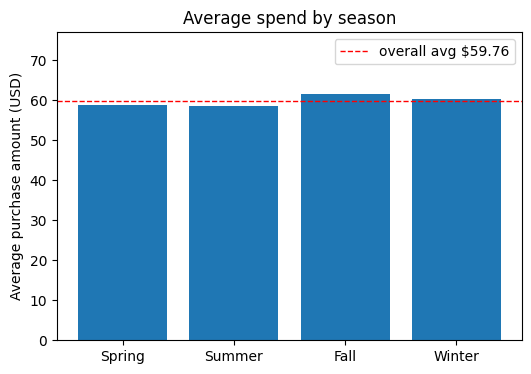

In [17]:
season = summarize('season').reindex(['Spring', 'Summer', 'Fall', 'Winter']); display(season)
plt.figure(figsize=(6, 4)); bar_avg(season, 'Average spend by season'); plt.show()

### Payment method

,customers,avg_spend,revenue,pct_customers,pct_revenue
payment_method,,,,,
Credit Card,671,60.07,40310,17.21,17.29
PayPal,677,59.25,40109,17.36,17.21
Cash,670,59.70,40002,17.18,17.16
Debit Card,636,60.92,38742,16.31,16.62
Venmo,634,58.95,37374,16.26,16.03
Bank Transfer,612,59.71,36544,15.69,15.68


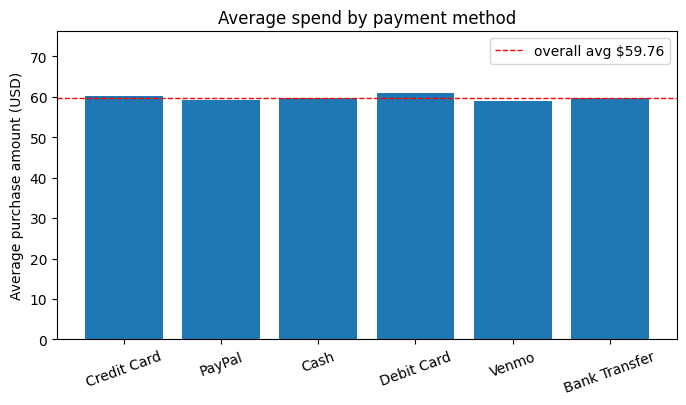

In [18]:
pay = summarize('payment_method').sort_values('revenue', ascending=False); display(pay)
plt.figure(figsize=(8, 4)); bar_avg(pay, 'Average spend by payment method', rotate=20); plt.show()

### Discount vs. spend

,customers,avg_spend,revenue,pct_customers,pct_revenue
discount_applied,,,,,
No,2223,60.13,133670,57.0,57.35
Yes,1677,59.28,99411,43.0,42.65


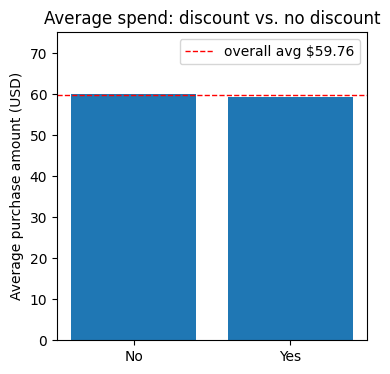

In [19]:
disc = summarize('discount_applied'); display(disc)
plt.figure(figsize=(4, 4)); bar_avg(disc, 'Average spend: discount vs. no discount'); plt.show()

### Shipping type (all 6) and offline proxy

,customers,avg_spend,revenue,pct_customers,pct_revenue
shipping_type,,,,,
2-Day Shipping,627,60.73,38080,16.08,16.34
Express,646,60.48,39067,16.56,16.76
Free Shipping,675,60.41,40777,17.31,17.49
Store Pickup,650,59.89,38931,16.67,16.70
Next Day Air,648,58.63,37993,16.62,16.30
Standard,654,58.46,38233,16.77,16.40


,customers,avg_spend,revenue,pct_customers,pct_revenue
channel_proxy,,,,,
Delivery,3250,59.74,194150,83.33,83.3
Offline proxy (Store Pickup),650,59.89,38931,16.67,16.7


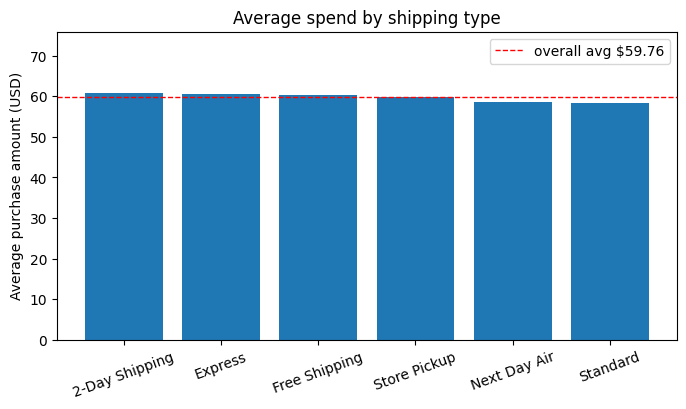

In [20]:
ship = summarize('shipping_type').sort_values('avg_spend', ascending=False); display(ship)

df['channel_proxy'] = np.where(df['shipping_type'] == 'Store Pickup', 'Offline proxy (Store Pickup)', 'Delivery')
display(summarize('channel_proxy'))

plt.figure(figsize=(8, 4)); bar_avg(ship, 'Average spend by shipping type', rotate=20); plt.show()

### Review rating vs. spend

,customers,avg_spend,revenue,pct_customers,pct_revenue
rating_band,,,,,
<3.0,680,58.51,39786,17.44,17.07
3.0-3.49,798,59.90,47797,20.46,20.51
3.5-3.99,788,59.14,46603,20.21,19.99
4.0-4.49,803,60.39,48495,20.59,20.81
4.5-5.0,831,60.65,50400,21.31,21.62


Correlation (rating, purchase_amount): 0.03


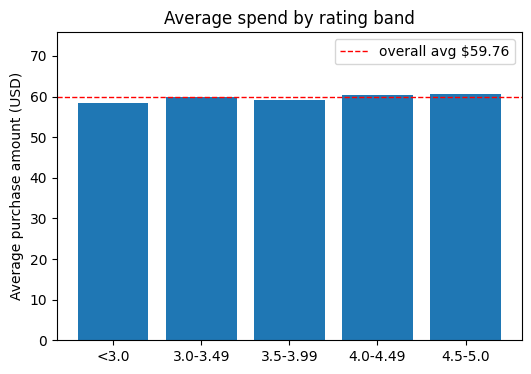

In [21]:
df['rating_band'] = pd.cut(df['review_rating'], bins=[0, 2.99, 3.49, 3.99, 4.49, 5.0],
                           labels=['<3.0', '3.0-3.49', '3.5-3.99', '4.0-4.49', '4.5-5.0'])
rating = summarize('rating_band'); display(rating)
print("Correlation (rating, purchase_amount):", round(df['review_rating'].corr(df['purchase_amount']), 3))
plt.figure(figsize=(6, 4)); bar_avg(rating, 'Average spend by rating band'); plt.show()

### Purchase frequency vs. spend

,customers,avg_spend,revenue
purchase_frequency_days,,,
7,539,58.97,31786
14,1089,59.88,65207
30,553,59.33,32810
90,1147,60.03,68859
365,572,60.17,34419


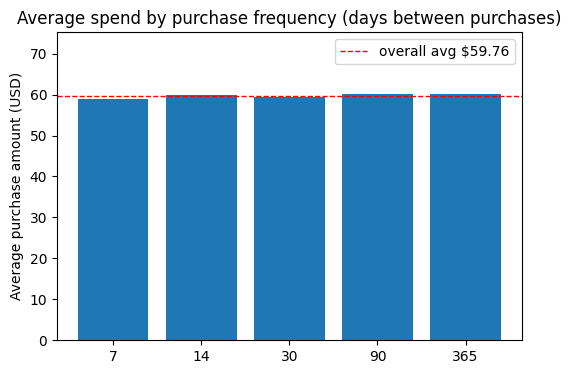

In [22]:
freq = (df.groupby('purchase_frequency_days')['purchase_amount']
          .agg(customers='count', avg_spend='mean', revenue='sum').round(2))
display(freq)
plt.figure(figsize=(6, 4)); bar_avg(freq, 'Average spend by purchase frequency (days between purchases)'); plt.show()

### Location: top and bottom 10 states by revenue

In [23]:
loc = summarize('location').sort_values('revenue', ascending=False)
display(pd.concat([loc.head(10).assign(group='Top 10'), loc.tail(10).assign(group='Bottom 10')]))

,customers,avg_spend,revenue,pct_customers,pct_revenue,group
location,,,,,,
Montana,96,60.25,5784,2.46,2.48,Top 10
Illinois,92,61.05,5617,2.36,2.41,Top 10
California,95,59.00,5605,2.44,2.40,Top 10
Idaho,93,60.08,5587,2.38,2.40,Top 10
Nevada,87,63.38,5514,2.23,2.37,Top 10
Alabama,89,59.11,5261,2.28,2.26,Top 10
New York,87,60.43,5257,2.23,2.26,Top 10
North Dakota,83,62.89,5220,2.13,2.24,Top 10
West Virginia,81,63.88,5174,2.08,2.22,Top 10


### Category and category × season

,customers,avg_spend,revenue,pct_customers,pct_revenue
category,,,,,
Clothing,1737,60.03,104264,44.54,44.73
Accessories,1240,59.84,74200,31.79,31.83
Footwear,599,60.26,36093,15.36,15.49
Outerwear,324,57.17,18524,8.31,7.95


season,Spring,Summer,Fall,Winter
category,,,,
Accessories,17007,19028,19874,18291
Clothing,27692,23078,26220,27274
Footwear,9555,9393,8665,8480
Outerwear,4425,4278,5259,4562


season,Spring,Summer,Fall,Winter
category,,,,
Accessories,22.9,25.6,26.8,24.7
Clothing,26.6,22.1,25.1,26.2
Footwear,26.5,26.0,24.0,23.5
Outerwear,23.9,23.1,28.4,24.6


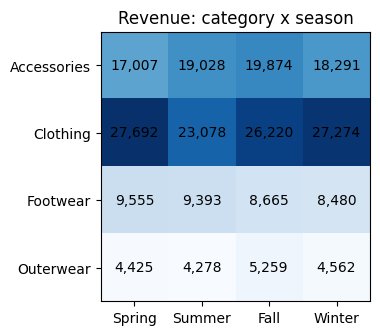

In [24]:
cat = summarize('category').sort_values('revenue', ascending=False); display(cat)

cs = df.pivot_table(index='category', columns='season', values='purchase_amount', aggfunc='sum')[['Spring', 'Summer', 'Fall', 'Winter']]
display(cs)
display((cs.div(cs.sum(axis=1), axis=0) * 100).round(1))   # each category's seasonal split (%)

fig, ax = plt.subplots(figsize=(6, 3.5))
im = ax.imshow(cs.values, cmap='Blues')
ax.set_xticks(range(cs.shape[1])); ax.set_xticklabels(cs.columns)
ax.set_yticks(range(cs.shape[0])); ax.set_yticklabels(cs.index)
for i in range(cs.shape[0]):
    for j in range(cs.shape[1]):
        ax.text(j, i, f"{cs.values[i, j]:,}", ha='center', va='center')
ax.set_title('Revenue: category x season'); plt.show()

### Age group and customer segment

In [25]:
age = summarize('age_group'); display(age)
seg = summarize('customer_segment').reindex(['New', 'Returning', 'Loyal']); display(seg)

,customers,avg_spend,revenue,pct_customers,pct_revenue
age_group,,,,,
Young Adult,1028,60.45,62143,26.36,26.66
Adult,942,59.42,55978,24.15,24.02
Middle-aged,986,60.04,59197,25.28,25.40
Senior,944,59.07,55763,24.21,23.92


,customers,avg_spend,revenue,pct_customers,pct_revenue
customer_segment,,,,,
New,1014,60.14,60980,26.00,26.16
Returning,1958,59.47,116444,50.21,49.96
Loyal,928,59.98,55657,23.79,23.88


## Statistical tests: are the differences real?
Welch t-test and Mann-Whitney U for two-group comparisons, ANOVA and Kruskal-Wallis for 3+ groups, Spearman for rating vs. spend.
With 9 tests run, a stricter threshold (Bonferroni: 0.05 / 9 ≈ 0.006) is safer than 0.05.

In [26]:
def compare(mask_a, mask_b, label):
    a = df.loc[mask_a, 'purchase_amount']; b = df.loc[mask_b, 'purchase_amount']
    return {'comparison': label,
            'mean_A': round(a.mean(), 2), 'mean_B': round(b.mean(), 2),
            'diff': round(a.mean() - b.mean(), 2),
            'p_welch_t': round(stats.ttest_ind(a, b, equal_var=False).pvalue, 4),
            'p_mann_whitney': round(stats.mannwhitneyu(a, b).pvalue, 4)}

rows = [
    compare(df.subscription_status == 'Yes', df.subscription_status == 'No', 'Subscribers vs. non-subscribers'),
    compare(df.shipping_type == 'Express',   df.shipping_type == 'Standard', 'Express vs. Standard shipping'),
    compare(df.discount_applied == 'Yes',    df.discount_applied == 'No',    'Discount vs. no discount'),
    compare(df.gender == 'Male',             df.gender == 'Female',          'Male vs. Female'),
    compare(df.channel_proxy.str.startswith('Offline'), df.channel_proxy == 'Delivery', 'Store Pickup vs. Delivery'),
]
tests = pd.DataFrame(rows)

# 3+ group tests
def multi(col):
    groups = [g['purchase_amount'].values for _, g in df.groupby(col, observed=True)]
    return stats.f_oneway(*groups).pvalue, stats.kruskal(*groups).pvalue
for col in ['season', 'payment_method', 'age_group']:
    p_a, p_k = multi(col)
    tests.loc[len(tests)] = [f'{col} (all groups)', np.nan, np.nan, np.nan, round(p_a, 4), round(p_k, 4)]

rho, p_rho = stats.spearmanr(df['review_rating'], df['purchase_amount'])
tests.loc[len(tests)] = [f'rating vs. spend (Spearman rho={rho:.3f})', np.nan, np.nan, np.nan, round(p_rho, 4), np.nan]

tests['significant_at_0.05'] = tests['p_welch_t'] < 0.05
tests

,comparison,mean_A,mean_B,diff,p_welch_t,p_mann_whitney,significant_at_0.05
0,Subscribers vs. non-subscribers,59.49,59.87,-0.37,0.6603,0.6657,False
1,Express vs. Standard shipping,60.48,58.46,2.01,0.1311,0.1425,False
2,Discount vs. no discount,59.28,60.13,-0.85,0.2661,0.2607,False
3,Male vs. Female,59.54,60.25,-0.71,0.3778,0.3715,False
4,Store Pickup vs. Delivery,59.89,59.74,0.16,0.8796,0.8713,False
5,season (all groups),NaN,NaN,NaN,0.0106,0.0098,True
6,payment_method (all groups),NaN,NaN,NaN,0.7465,0.7455,False
7,age_group (all groups),NaN,NaN,NaN,0.5733,0.5717,False
8,rating vs. spend (Spearman rho=0.029),NaN,NaN,NaN,0.0673,NaN,False


**How to read this:** a p-value above 0.05 means the observed gap is within what random variation would produce, so it should **not** be presented as a business driver.
Statistically significant results with tiny gaps (a few dollars on a ~$60 average) still deserve a cautious wording.

## Key takeaways (verified on this dataset)
- Total revenue **$233,081** across 3,900 customers, average **$59.76**.
- **Gender:** 68% male / 32% female customers with nearly equal spend per customer ($59.54 vs. $60.25). Female customers are under-acquired.
- **Subscribers do not spend more** ($59.49 vs. $59.87, not significant). Subscribers are 27% of customers and 26.9% of revenue.
- **Discounts do not lift spend:** discounted purchases average $59.28 vs. $60.13 without a discount (not significant). 43% of purchases use a discount, so margin is being given away without a measurable spend gain.
- **Shipping, payment method, age group, review rating and purchase frequency show no meaningful spend differences.**
- **Season is the only borderline signal:** Fall averages $61.56 vs. Summer $58.41 (p ≈ 0.01: significant at 0.05 but not after multiple-test correction, and the gap is only ~$3).
- **Category mix is the strongest structural pattern:** Clothing 44.7% of revenue, Accessories 31.8%, Footwear 15.5%, Outerwear 7.9%.

## Export the cleaned data (for Power BI and the SQL load)

In [27]:
df.drop(columns=['channel_proxy', 'rating_band']).to_csv('customer_shopping_behavior_clean.csv', index=False)
df = df.drop(columns=['channel_proxy', 'rating_band'])   # keep the DB table limited to the cleaned schema
df.shape

(3900, 20)

Database Connection - PostgreSQL

In [28]:
%pip install python-dotenv psycopg2-binary sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [29]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import URL, create_engine, text

env_path = Path.cwd() / ".env"
if not env_path.is_file():
    raise FileNotFoundError(f".env not found at {env_path.resolve()}")

load_dotenv(env_path, override=True)

required = ("DB_USERNAME", "DB_PASSWORD", "DB_HOST", "DB_PORT", "DB_NAME")
missing = [key for key in required if not os.getenv(key)]
if missing:
    raise ValueError(f"Missing values in .env: {', '.join(missing)}")

engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.environ["DB_USERNAME"],
    password=os.environ["DB_PASSWORD"],
    host=os.environ["DB_HOST"],
    port=int(os.environ["DB_PORT"]),
    database=os.environ["DB_NAME"],
))

with engine.connect() as connection:
    print(connection.execute(
        text("SELECT current_database(), current_user")
    ).one())

table_name = "customer"
df.to_sql(table_name, engine, if_exists="replace", index=False)
print(f"Data successfully loaded into table '{table_name}'.")

('customer_behavior', 'postgres')
Data successfully loaded into table 'customer'.
